# Cat and Dog Facial Feature Classification

**Goal:** train a deep learning model that looks at an image and decides which of 8 classes it belongs to (CatEye, DogEye, CatFace, DogFace, CatMouth, DogMouth, CatNose, DogNose).



### Task 1: Dataset Exploration and Understanding

In [2]:
import torch
import pandas as pd
from pathlib import Path

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

DATA_DIR = Path(".")
TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "test"

# Loading the labels
labels_df = pd.read_csv(DATA_DIR / "train_labels.csv", dtype=str)
print(labels_df.head())
print("Columns:", list(labels_df.columns))


Using device: cpu
  image_id     class
0    00001    DogEye
1    00002  DogMouth
2    00003   DogFace
3    00004   DogNose
4    00005   DogNose
Columns: ['image_id', 'class']


In [4]:
id_col, class_col = labels_df.columns[0], labels_df.columns[1]

# Lists everything
files = {}
for p in TRAIN_DIR.rglob("*"):
    if p.is_file():
        files[p.name] = p
        files[p.stem] = p

# Stores id in new column path
labels_df["path"] = labels_df[id_col].map(files)
print("Labels with no matching image file:", labels_df["path"])
labels_df = labels_df.dropna(subset=["path"]).reset_index(drop=True)

# New column for image's class number
classes = sorted(labels_df[class_col].unique())
class_to_idx = {name: i for i, name in enumerate(classes)}
labels_df["y"] = labels_df[class_col].map(class_to_idx)

print("Classes:", classes)
print("Class -> number:", class_to_idx)
print("Training images:", len(labels_df))

Labels with no matching image file: 0        train\train\00001.jpg
1        train\train\00002.jpg
2        train\train\00003.jpg
3        train\train\00004.jpg
4        train\train\00005.jpg
                 ...          
63655    train\train\63656.jpg
63656    train\train\63657.jpg
63657    train\train\63658.jpg
63658    train\train\63659.jpg
63659    train\train\63660.jpg
Name: path, Length: 63660, dtype: object
Classes: ['CatEye', 'CatFace', 'CatMouth', 'CatNose', 'DogEye', 'DogFace', 'DogMouth', 'DogNose']
Class -> number: {'CatEye': 0, 'CatFace': 1, 'CatMouth': 2, 'CatNose': 3, 'DogEye': 4, 'DogFace': 5, 'DogMouth': 6, 'DogNose': 7}
Training images: 63660


class
CatEye      13884
CatFace      6942
CatMouth     6942
CatNose      6942
DogEye      11580
DogFace      5790
DogMouth     5790
DogNose      5790
Name: count, dtype: int64


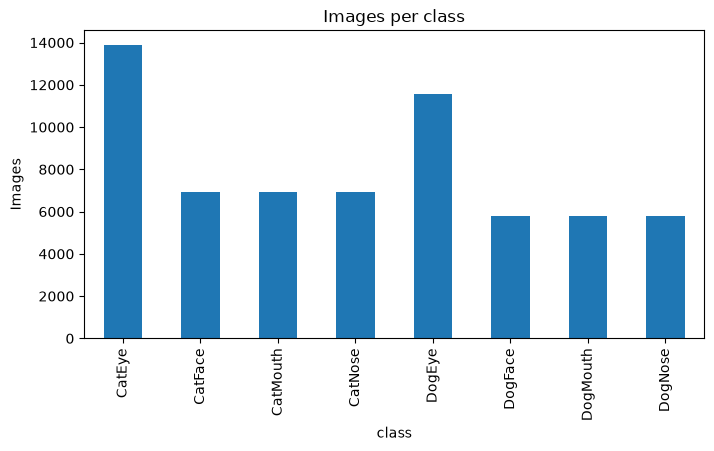

In [5]:
import matplotlib.pyplot as plt

counts = labels_df[class_col].value_counts().reindex(classes)
print(counts)

# Bar chart plot
counts.plot(kind="bar", title="Images per class", figsize=(8, 4))
plt.ylabel("Images")
plt.show()

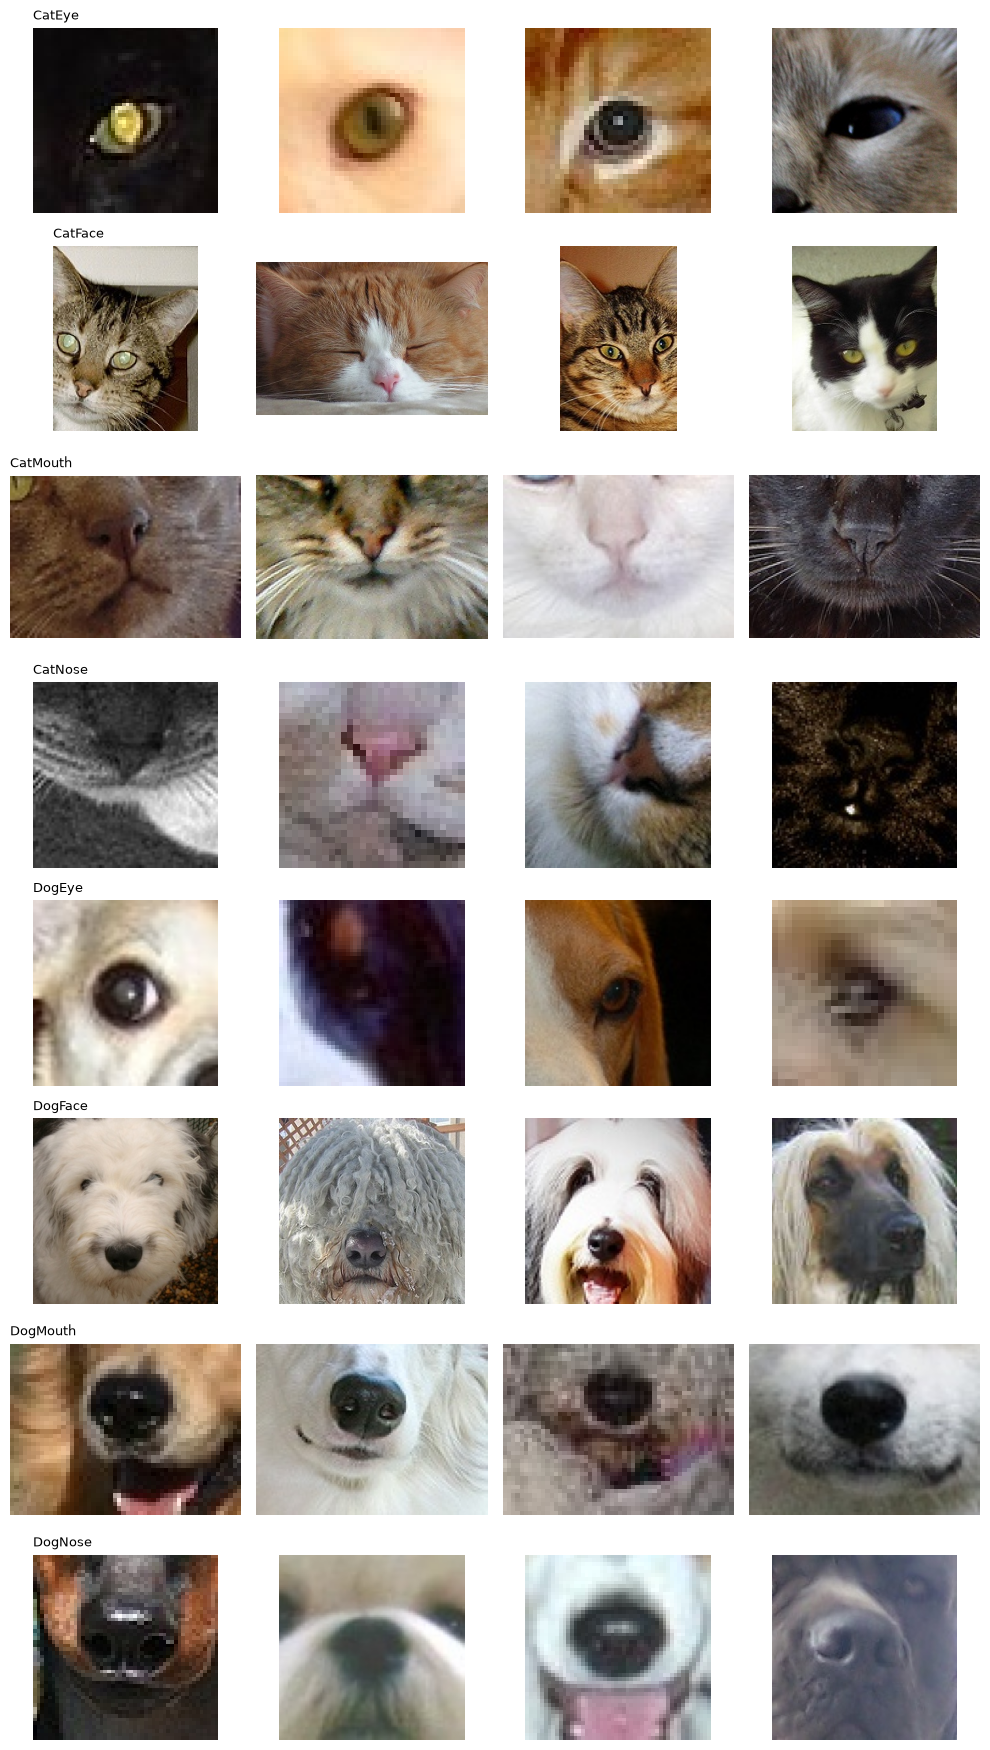

In [ ]:
from PIL import Image

# Sample images for each class
# 4 Random Images
fig, axes = plt.subplots(len(classes), 4, figsize=(10, 2.2 * len(classes)))
for row, cls in enumerate(classes):
    samples = labels_df[labels_df[class_col] == cls].sample(4, random_state=42)["path"]
    for col, path in enumerate(samples):
        axes[row, col].imshow(Image.open(path).convert("RGB"))
        axes[row, col].axis("off")
    axes[row, 0].set_title(cls, loc="left", fontsize=9)
plt.tight_layout()
plt.show()

In [7]:
from collections import Counter

# Checking for broken files and different sizes
sizes, broken = Counter(), []
for path in labels_df["path"]:
    try:
        with Image.open(path) as im:
            sizes[im.size] += 1
    except Exception:
        broken.append(path)

print("Corrupted files:", len(broken))
print("Number of different image sizes:", len(sizes))
print("Most common sizes:", sizes.most_common(5))

Corrupted files: 0
Number of different image sizes: 7861
Most common sizes: [((40, 40), 1062), ((48, 48), 1051), ((42, 42), 1050), ((38, 38), 1002), ((44, 44), 1002)]


In [9]:
# Testing data structure
sample_sub = pd.read_csv(DATA_DIR / "sample_submission.csv", dtype=str)
print(sample_sub.head())
print("Test images listed:", len(sample_sub))
print("Files in test folder:", len([p for p in TEST_DIR.iterdir() if p.is_file()]))

  image_id     class
0        1    DogEye
1        2   CatNose
2        3   CatNose
3        4   DogFace
4        5  DogMouth
Test images listed: 29443
Files in test folder: 0


### Task 2: Preprocessing

In [ ]:
from torchvision import transforms

MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

# Transforming the images for training and data augmentation
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(0.2, 0.2, 0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# Validation and Testing random images
eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])